<a href="https://colab.research.google.com/github/rama603/Reading-Sign-Language-/blob/main/Reading_Sign_Language.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load datasets
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

# Extract features and labels
X_train = train_df.drop(columns="label").values.astype("float32") / 255.0
y_train = train_df["label"].values

X_test = test_df.drop(columns="label").values.astype("float32") / 255.0
y_test = test_df["label"].values

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (27455, 784)
Test data shape: (7172, 784)


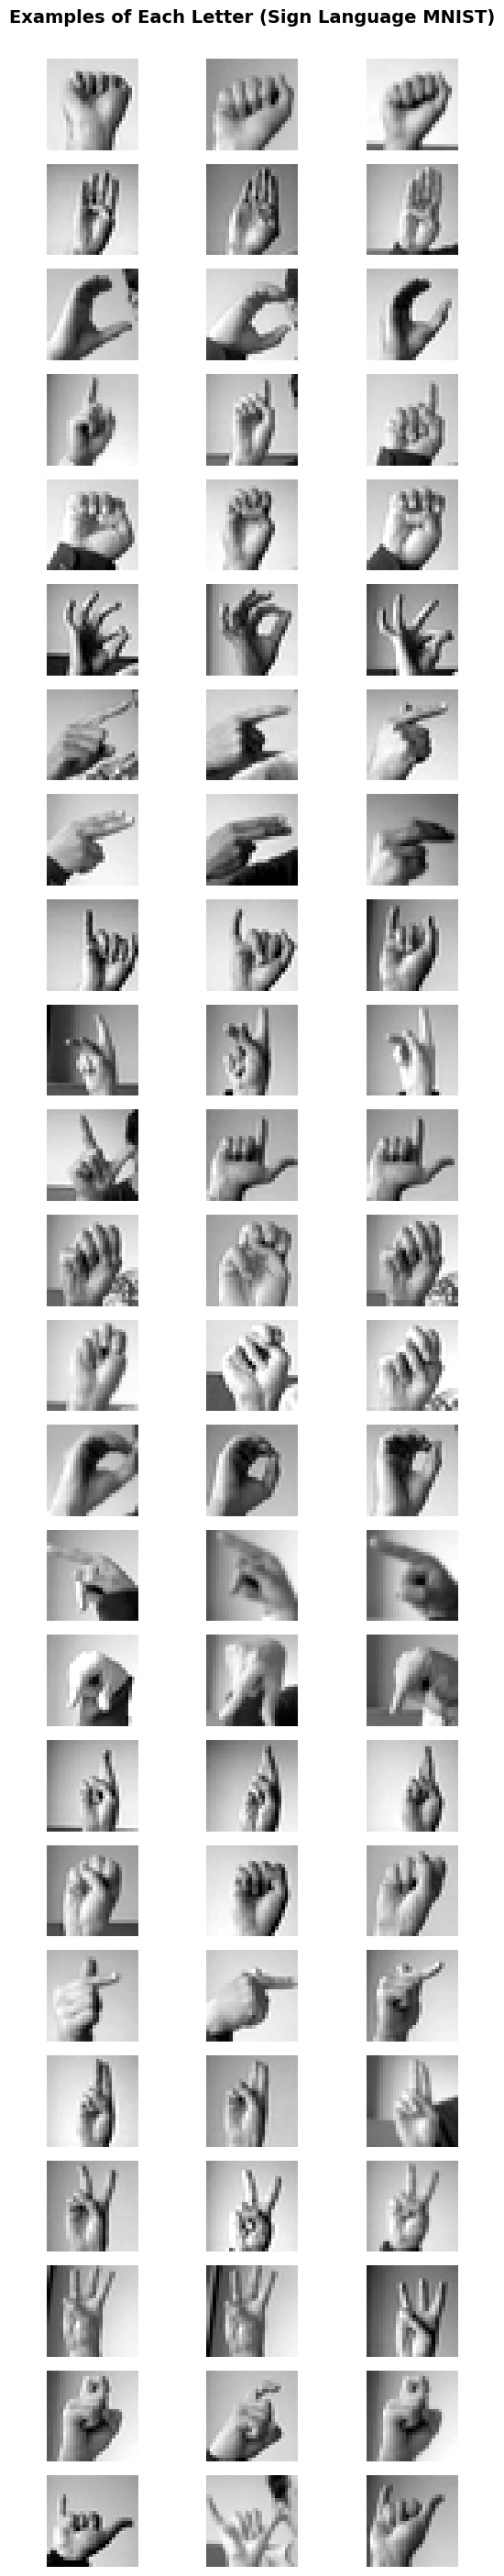

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Map labels 0-24 to letters A-Y (skipping J which is index 9)
def get_letter(label):
    if label < 9:
        return chr(ord('A') + label)
    else:
        return chr(ord('A') + label + 1)

unique_labels = sorted(np.unique(y_train))
num_samples_per_letter = 3

fig, axes = plt.subplots(len(unique_labels), num_samples_per_letter, figsize=(6, 28))

for i, label in enumerate(unique_labels):
    letter = get_letter(label)
    idxs = np.where(y_train == label)[0]
    sample_idxs = idxs[:num_samples_per_letter] # Grab 3 examples for this letter

    for j, idx in enumerate(sample_idxs):
        ax = axes[i, j]
        ax.imshow(X_train[idx].reshape(28, 28), cmap='gray')
        ax.axis('off')
        # Label the first column with the letter name
        if j == 0:
            ax.set_ylabel(letter, rotation=0, fontsize=12, labelpad=15, va='center', fontweight='bold')

plt.suptitle("Examples of Each Letter (Sign Language MNIST)", y=1.002, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()